Electrode map generator
this interface automatically reads electrode layouts from dxf files,
and maps channels to PCB channels.

return: 3 x n_channels matrix (x-location, y-loction, PCB channel)

In [21]:
file_name = "electrode-headstage_connection.csv"

In [22]:
import math, numpy as np, matplotlib.pyplot as plt, ezdxf, csv
import utils

In [23]:
from utils import read_electrode_centroids, print_text

In [24]:
utils.read_electrode_centroids("../example2/Xiaomin_electrode_v2.dxf", layer_name="electrodes")


Found 64 closed contact contours.


array([[ 773.5,  982.8],
       [-749.5,  967.2],
       [ 749.5,  951.6],
       [-725.5,  936. ],
       [ 725.5,  920.4],
       [-701.5,  904.8],
       [ 701.5,  889.2],
       [-677.5,  873.6],
       [ 677.5,  858. ],
       [-653.5,  842.4],
       [ 653.5,  826.8],
       [-629.5,  811.2],
       [ 629.5,  795.6],
       [-605.5,  780. ],
       [ 605.5,  764.4],
       [-581.5,  748.8],
       [ 581.5,  733.2],
       [-557.5,  717.6],
       [ 557.5,  702. ],
       [-533.5,  686.4],
       [ 533.5,  670.8],
       [-509.5,  655.2],
       [ 509.5,  639.6],
       [-485.5,  624. ],
       [ 485.5,  608.4],
       [-461.5,  592.8],
       [ 461.5,  577.2],
       [-437.5,  561.6],
       [ 437.5,  546. ],
       [-413.5,  530.4],
       [ 413.5,  514.8],
       [-389.5,  499.2],
       [ 389.5,  483.6],
       [-365.5,  468. ],
       [ 365.5,  452.4],
       [-341.5,  436.8],
       [ 341.5,  421.2],
       [-317.5,  405.6],
       [ 317.5,  390. ],
       [-293.5,  374.4],


In [25]:

xy = read_electrode_centroids("../example2/Xiaomin_electrode_v2.dxf", layer_name="electrodes")


Found 64 closed contact contours.


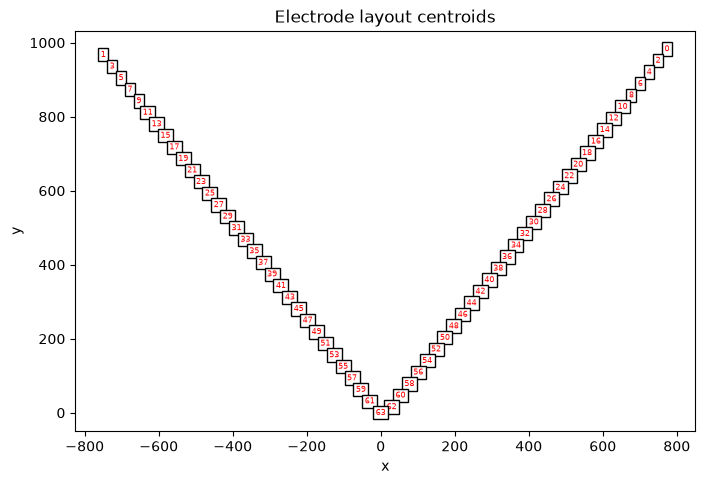

In [26]:
fig, ax = plt.subplots(figsize=(8, 10))

for i, (x, y) in enumerate(xy):
    utils.print_text(ax, i, [x, y])

ax.scatter(xy[:, 0], xy[:, 1], s=20, color="tab:blue", alpha=0.7)
ax.set_aspect("equal")
ax.set_title("Electrode layout centroids")
ax.set_xlabel("x")
ax.set_ylabel("y")
plt.show()

In [31]:
# Read the CSV mapping
with open(file_name, newline="") as file:
    reader = csv.DictReader(file, delimiter=";")
    mapping_rows = [
        row for row in reader
        if row["Electrode Channel"].strip()
    ]

# Create a 3 x n matrix in electrode-channel order
n_channels = len(mapping_rows)
channel_map = np.zeros((3, n_channels), dtype=float)

# Match each electrode channel to its centroid
for row in mapping_rows:
    electrode_channel = int(row["Electrode Channel"])
    connector_channel = int(row["Connector Channel"])

    # TODO: do we want to 0-index electrode channels?
    # electrode channels are 1-indexed, xy array is 0-indexed
    centroid_index = electrode_channel - 1

    channel_map[0, centroid_index] = xy[centroid_index, 0]
    channel_map[1, centroid_index] = xy[centroid_index, 1]
    channel_map[2, centroid_index] = connector_channel


print(channel_map.shape)
print(channel_map[:, 1])

(3, 64)
[-749.5  967.2   53. ]
